# Predicting Sales Prices

 ## Dataset Attributes

 The dataset contains information about houses in Ames, Iowa. The data was collected by the Ames City Assessor’s Office describing 2930 property sales which occurred in Ames, Iowa between 2006 and 2010. The dataset, containing 81 variables, was compiled and published by De Cock in 2011.

 Some of the variables contained in the original dataset have been removed from the the dataset provided to you.
 The dataset provided to you contains the following variables:
* **Year_Built:** year that the house was originally constructed
* **Year_Remod_Add:** year that the house was last remodelled
* **Total_Bsmt_SF:** total size of basement area in square feet
* **First_Flr_SF:** size of the first floor in square feet
* **Second_Flr_SF:** size of the second floor in square feet
* **Gr_Liv_Area:** size of above grade, ground living area in square feet
* **Full_Bath:** number of full above grade bathrooms in the house
* **Half_Bath:** number of half above grade bathrooms in the house
* **Bedroom_AbvGr:** number of above grade bedrooms (does not include basement bedrooms)
* **Kitchen_AbvGr:** number of above grade kitchens
* **TotRms_AbvGrd:** total number of above grade rooms (does not include bathrooms)
* **Fireplaces:** number of fireplaces in the house
* **Garage_Area:** size of garage in square feet
* **Sale_Price:** sale price of the house in dollars


*De Cock, D. (2011). "Ames, Iowa: Alternative to the Boston Housing Data as an End of Semester
Regression Project," Journal of Statistics Education, Volume 19, Number 3.*

- https://ww2.amstat.org/publications/jse/v19n3/decock/DataDocumentation.txt
- http://ww2.amstat.org/publications/jse/v19n3/decock.pdf


 ## Objective

 The goal of this task is to analyse the relationship between these variables and build a multiple linear regression model to predict the sales prices based on the 'Gr_Liv_Area' and 'Garage_Area` variables.


In [39]:
# Import libraries
import numpy as np 
import pandas as pd 
import seaborn as sns
import matplotlib.pyplot as plt 
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import root_mean_squared_error, r2_score, mean_squared_error 


%matplotlib inline


In [40]:
# Read in the data set
ames_data = pd.read_csv('ames.csv')
ames_data.head()


,Year_Built,Year_Remod_Add,Total_Bsmt_SF,First_Flr_SF,Second_Flr_SF,Gr_Liv_Area,Full_Bath,Half_Bath,Bedroom_AbvGr,Kitchen_AbvGr,TotRms_AbvGrd,Fireplaces,Garage_Area,Sale_Price
0,1960,1960,1080,1656,0,1656,1,0,3,1,7,2,528,215000
1,1961,1961,882,896,0,896,1,0,2,1,5,0,730,105000
2,1958,1958,1329,1329,0,1329,1,1,3,1,6,0,312,172000
3,1968,1968,2110,2110,0,2110,2,1,3,1,8,2,522,244000
4,1997,1998,928,928,701,1629,2,1,3,1,6,1,482,189900


## Clean and pre-process the data if neccessary

In [41]:
# no missing values and dtype is int64
missing_values_count = ames_data.isnull().sum()
missing_values_count[:]



Year_Built        0
Year_Remod_Add    0
Total_Bsmt_SF     0
First_Flr_SF      0
Second_Flr_SF     0
Gr_Liv_Area       0
Full_Bath         0
Half_Bath         0
Bedroom_AbvGr     0
Kitchen_AbvGr     0
TotRms_AbvGrd     0
Fireplaces        0
Garage_Area       0
Sale_Price        0
dtype: int64

In [42]:
# This gives a full in-depth info about our columns and 
# the data types of each column and whether they are correct or not. 
ames_data.info(memory_usage='deep')

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2930 entries, 0 to 2929
Data columns (total 14 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   Year_Built      2930 non-null   int64
 1   Year_Remod_Add  2930 non-null   int64
 2   Total_Bsmt_SF   2930 non-null   int64
 3   First_Flr_SF    2930 non-null   int64
 4   Second_Flr_SF   2930 non-null   int64
 5   Gr_Liv_Area     2930 non-null   int64
 6   Full_Bath       2930 non-null   int64
 7   Half_Bath       2930 non-null   int64
 8   Bedroom_AbvGr   2930 non-null   int64
 9   Kitchen_AbvGr   2930 non-null   int64
 10  TotRms_AbvGrd   2930 non-null   int64
 11  Fireplaces      2930 non-null   int64
 12  Garage_Area     2930 non-null   int64
 13  Sale_Price      2930 non-null   int64
dtypes: int64(14)
memory usage: 320.6 KB


Now we rename our columns for easier calling within the code. Since we are only measure Gr_Living_Area and Garage_Size against Sales_Price, we will rename these columns.  

In [43]:
# Create new Dataframe for our specified analyses
ames_subset_df = pd.DataFrame({
    'living_area' : ames_data['Gr_Liv_Area'],
    'garage' : ames_data['Garage_Area'],
    'price' : ames_data['Sale_Price']
})


## Explore the data with visualisations such as histograms and correlation matrices


In [44]:
# Explore the data with visualisations such as histograms and correlation matrices

correlation_matrix = ames_subset_df[['living_area', 'garage', 'price']].corr()

print(correlation_matrix)


             living_area    garage     price
living_area     1.000000  0.483971  0.706780
garage          0.483971  1.000000  0.640138
price           0.706780  0.640138  1.000000


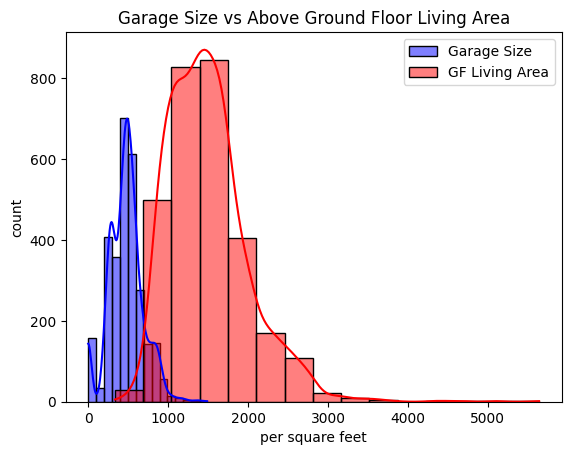

In [45]:
sns.histplot(data=ames_subset_df['garage'], color='blue', label='Garage Size', bins=15, kde=True)
sns.histplot(data=ames_subset_df['living_area'], color='red', label='GF Living Area', bins=15, kde=True)

plt.title("Garage Size vs Above Ground Floor Living Area")
plt.xlabel('per square feet')
plt.ylabel('count')
plt.legend()
plt.show()
plt.close()


The histograms show the distributions of garage area and above-ground living areas across properties in the dataset. 
Garage sizes appear concentrated around common residential garage dimensions, while above-ground living area displays a right-skewed distribution, with a smaller number of properties having substantially larger living spaces. 

These distributions suggest that some properties may have unusually large values, which could influence the regression analysis. Further investigation of potential outliers and model residuals is therefore useful. 

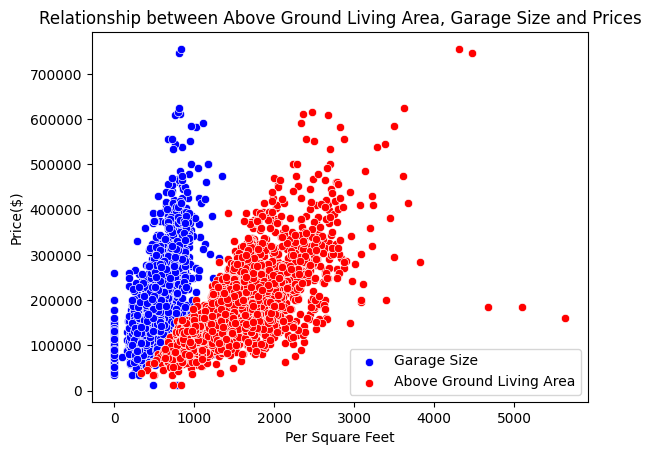

In [46]:
# Multi-plot grid to see the relationship between groundfloor and price
# garage size and price 

plt.figure()
sns.scatterplot(data=ames_subset_df, x='garage', y='price', label='Garage Size', color='blue')
sns.scatterplot(data=ames_subset_df, x='living_area', y='price', label='Above Ground Living Area', color='red')
plt.title("Relationship between Above Ground Living Area, Garage Size and Prices")
plt.xlabel('Per Square Feet')
plt.ylabel('Price($)')
plt.legend()
plt.show()
plt.close()

The sactterplot indicate positive relationships between property size characteristics and sale prices. 

Above-ground livign area has a stronger positive correlation with sale price (approximately 0.71) than garage area (approximately 0.64). 

Thei suggests that properties with larger living generally sell for higher prices. Garage area is also positively associated with sale price, although its relationship is somewhat weaker. 

However, correlation does not establish causation, and these relationships do not account for other property characteristics such as location, condition or age. 

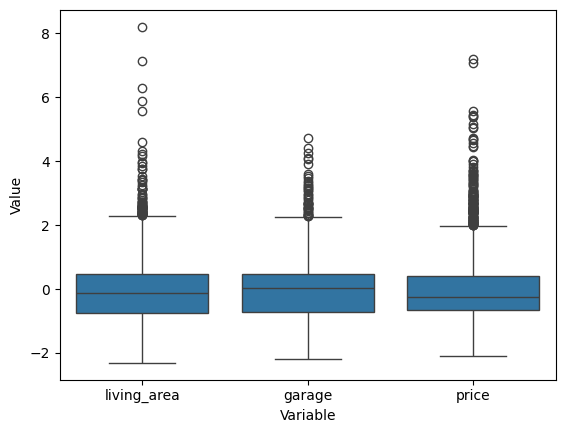

In [47]:
# Scaling data to find any outliers within our IVs and our DV
scaler=StandardScaler()
scaled_data = scaler.fit_transform(ames_subset_df)
scaled_data_df = pd.DataFrame(scaled_data, 
                              columns=['living_area',
                                       'garage',
                                       'price'])

# Melt and Plot original and scaled data to compare 
melted_df = pd.melt(scaled_data_df, var_name='Variable', value_name='Value')
sns.boxplot(melted_df, x='Variable', y='Value')
plt.show()


Seems that there are many outliers in both IVs and DV. Suggesting there needs to be some more data cleaning, however it is not necessary as the garage area column has data values of 0 which may be seen as an outlier, but can be valid data points, which could simply mean that the house does not have garages. Therefore, there was no reason to remove these 0 value records. In order to even out the outliers we can as previously mentioned, carry out a log transformation. 

## Explore relationships between the independent and dependent variables (Simple Linear Regression)


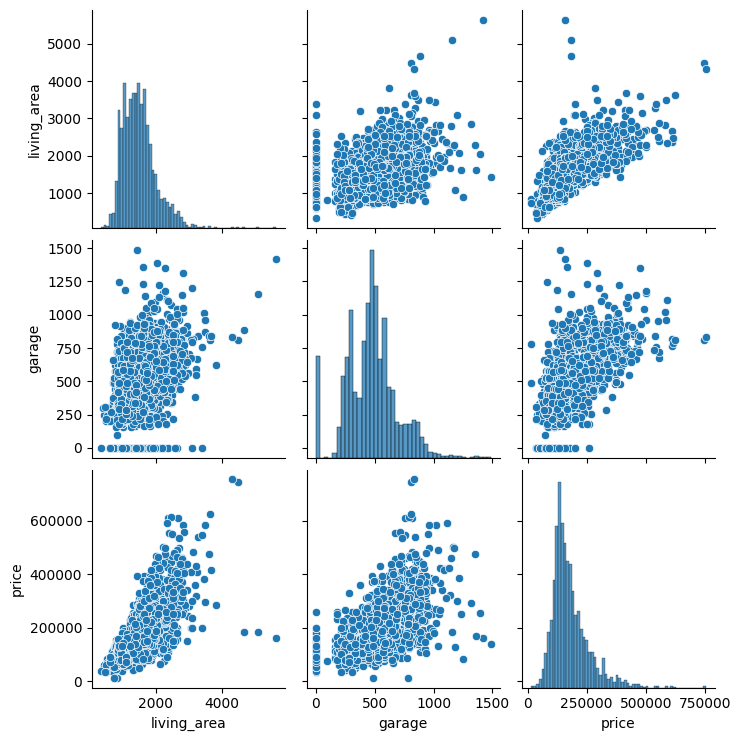

In [48]:
# Pairplot to visualise relationship between IVs and DV
sns.pairplot(ames_subset_df)
plt.show()

**Garage VS Price**

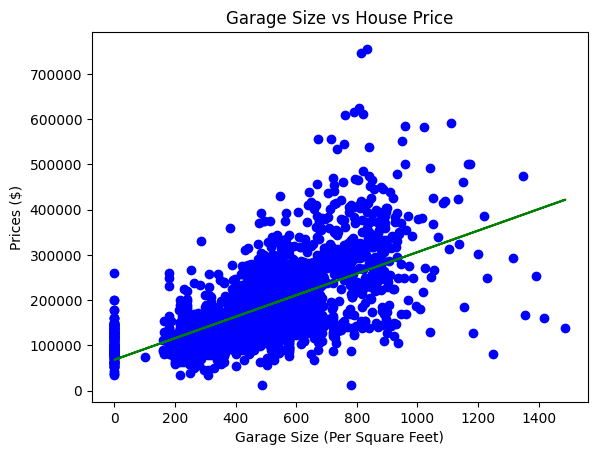

In [49]:
# Selected and reshaped data 
x = ames_subset_df.iloc[:, 1].values
y = ames_subset_df.iloc[:, 2].values
x=x.reshape(-1,1)
y=y.reshape(-1,1)

# Creating an empty linear regression model 
garage_model = LinearRegression()

# Fit the data into the model
garage_model.fit(x, y)

# Use model to make a prediction 
y_pred = garage_model.predict(x)

# Plot model and data
plt.scatter(x,y,color = 'b')
plt.plot(x, garage_model.predict(x),color ='g')
plt.title('Garage Size vs House Price')
plt.xlabel("Garage Size (Per Square Feet)")
plt.ylabel("Prices ($)")
plt.show()


In [50]:
print('Coefficeints: \n', garage_model.coef_)

Coefficeints: 
 [[237.64672033]]


The simple linear regression model estimates the relationship between garage area and sale price. 

THe coefficient represents predicted change in sale price associated with an additional square foot of garage area, without adjusting for above-ground living area or other property characteristics. 

The estomated relationship is positive, suggesting that properties with larger garages tend to gave higher sale prices. 

**Groundfloor Living Area vs Prices**

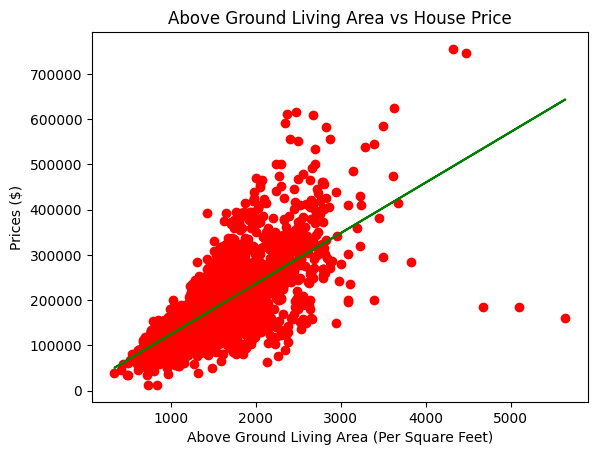

In [51]:
# Selected and reshaped data 
x = ames_subset_df.iloc[:, 0].values
y = ames_subset_df.iloc[:, 2].values
x=x.reshape(-1,1)
y=y.reshape(-1,1)

# Creating an empty linear regression model 
gf_area_model = LinearRegression()

# Fit the data into the model
gf_area_model.fit(x, y)

# Use model to make a prediction 
y_pred = gf_area_model.predict(x)

# Plot model and data
plt.scatter(x,y,color = 'r')
plt.plot(x, gf_area_model.predict(x),color ='g')
plt.title('Above Ground Living Area vs House Price')
plt.xlabel("Above Ground Living Area (Per Square Feet)")
plt.ylabel("Prices ($)")
plt.show()

In [52]:
print("Coefficeint:", gf_area_model.coef_)

Coefficeint: [[111.69400086]]


The simple linear regression model estimates the relationship between Above-ground living area and sale price. 

The coefficient indicates the predicted change in sale price associated with an additional square foot of above-groun dliving area, without controlling for garage area or other property characteristics. 

The positice relationship suggests that properties with larger above-ground living areas generally have higher sale prices. 


## Multiple Linear Regression

In [53]:
# Split the independent variables from the dependent variable
X = ames_subset_df[['garage','living_area']].values
X


array([[ 528, 1656],
       [ 730,  896],
       [ 312, 1329],
       ...,
       [   0,  970],
       [ 418, 1389],
       [ 650, 2000]], shape=(2930, 2))

In [54]:
y = ames_subset_df[['price']].values 
y

array([[215000],
       [105000],
       [172000],
       ...,
       [132000],
       [170000],
       [188000]], shape=(2930, 1))

In [55]:
# Create a training and test set with a 75:25 split ratio
rseed = 23 
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=rseed)

print('Training data:', X_train.shape, y_train.shape)
print('Test data:', X_test.shape, y_test.shape)


Training data: (2197, 2) (2197, 1)
Test data: (733, 2) (733, 1)


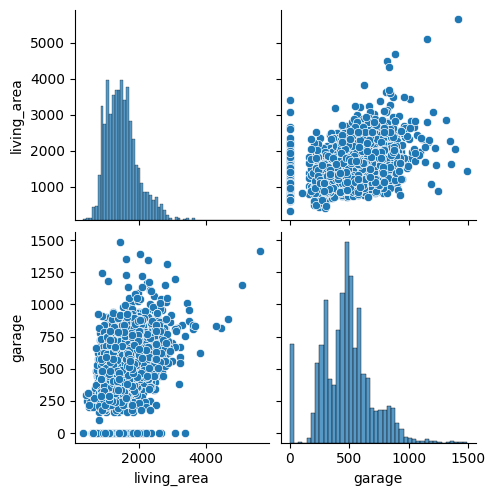

In [56]:
sns.pairplot(ames_subset_df[['living_area', 'garage']])


groundfloor follows a gaussian distribution, whereas garage_sizes does not and is rightly skewed. This won't need any scaling as the data is all measured in square feet so have the same measurements/scale. Also, it's not necessary but to get a more accurate and reliable multiple linear regression a log transformation can be performed to remove the rightly skewed data.

In [57]:
# Build a multiple linear regression model using 'Gr_Liv_Area' and 'Garage_Area'

# Fit model on training and test data
lm = LinearRegression()
model = lm.fit(X_train, y_train)
predictions = lm.predict(X_test)

# Create line coordinates 
X_line = np.empty(X_test.shape)
for i in range(X_test.shape[1]):
    X_line[:, i] = np.linspace(np.min(X_test[:, i]), np.max(X_test[:, i]), num=X_test.shape[0])
y_line=lm.predict(X_line)



In [58]:
# Print the model intercept and coefficients

print("Intercepts: \n", lm.intercept_)
print("Coefficeints: \n", lm.coef_)


Intercepts: 
 [-15408.30057694]
Coefficeints: 
 [[143.47756103  86.00612276]]


The multiple linear regression model esstimates the relationship between garage area, above-ground living area and property sale prices.

The garage area coefficient is approximately 143.48. This indicates that an additional square foot of garage area is associated with an estimated $143.48 increase in sale price, holding above-ground living area constant. 

The above-ground living area coefficiant is approximately 86.01. This indicates that an additional square foot of above-ground living area is associated with an estimated $86.01 increase in sale price, holding garage area constant. 

The model intercept is approximately -$15,408. This represents the predicted sale price when both garage area and living area equal zero. As this is not a realistic residential property scenario, the intercept has limited practical interpretation.

These coefficients describe statistical associations within the fitted model and should not be interpreted as casual effects. 

In [59]:
# Compare actual and predicted house prices 
comparison_df = pd.DataFrame({
    'Actual_Price': y_test.ravel(),
    'Predicted_Price': predictions.ravel()
})

comparison_df['Prediction_Error'] = (
    comparison_df['Actual_Price']
    - comparison_df['Predicted_Price']
)

comparison_df.head(10)

,Actual_Price,Predicted_Price,Prediction_Error
0,87000,105306.537973,-18306.537973
1,176485,159127.887870,17357.112130
2,158500,167769.096909,-9269.096909
3,98000,58900.989489,39099.010511
4,410000,364961.459477,45038.540523
5,170000,202735.404525,-32735.404525
6,222000,269013.984102,-47013.984102
7,316000,293627.013845,22372.986155
8,259000,206571.930700,52428.069300
9,140000,224376.806389,-84376.806389


In [60]:
# Evaluate the model
rmse = np.sqrt(mean_squared_error(y_test, predictions))
print("Rmse:", rmse)

r2 = r2_score(y_test, predictions)
print("R2:", r2)


Rmse: 53246.98852788171
R2: 0.5696221653633046


In [61]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

mae = mean_absolute_error(y_test, predictions)
rmse = np.sqrt(mean_squared_error(y_test, predictions))
r2 = r2_score(y_test, predictions)

print(f"Mean Absolute Erroe: ${mae:,.2f}")
print(f"Root Mean Squared Error: ${rmse:,.2f}")
print(f"R2 Score: {r2:.4f}")


Mean Absolute Erroe: $33,964.93
Root Mean Squared Error: $53,246.99
R2 Score: 0.5696


The multiple linear regression mdoel acheived an R2 score of approximatelt 0.57 on the test dataset, indicating that garage area and above-ground living area together explain approximately 57% of the variations of sale prices within the test sample. 

The RMSE was approximately $53,247, indicating that the model has considerable prdiction error, particularly because RMSE places greater weight on largert errors.

The MAE provides and additional measure of the average absolute difference between predicted and actual sale price. 

These results suggest tha the two selected property characteristics provide useful predictive information, but additional variables may be needed to improve accuracy. The model should therefore be viewed as an introductory predictive model rather than a reliable standalone property valuation tool. 

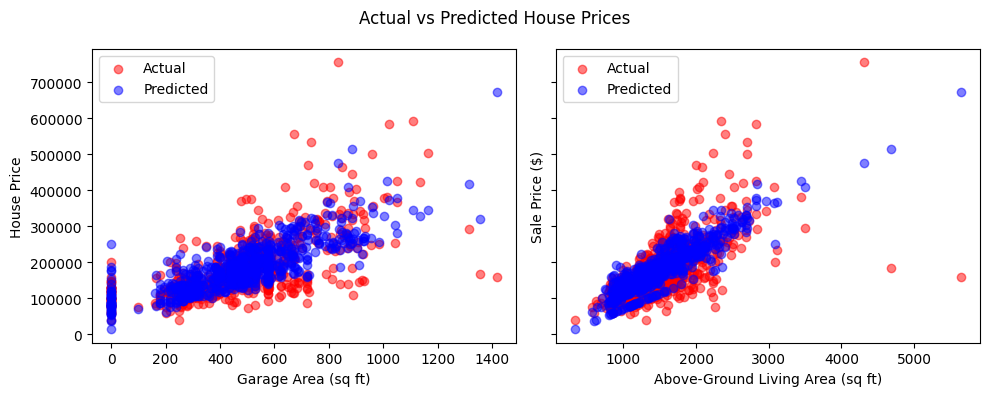

In [62]:
fig, ax = plt.subplots(1, X_test.shape[1], sharey=True, figsize=(10, 4))
fig.suptitle("Actual vs Predicted House Prices")

feature_names = [
    'Garage Area (sq ft)',
    'Above-Ground Living Area (sq ft)']

for i in range(X_test.shape[1]):
    ax[i].scatter(
        X_test[:, i], 
        y_test, 
        color='red', 
        label='Actual', 
        alpha=0.5
    )
    
    ax[i].scatter(
        X_test[:, i],
        predictions,
        color='blue',
        label='Predicted',
        alpha=0.5
    )
    
    ax[i].set_xlabel(feature_names[i])
    ax[i].set_ylabel('Sale Price ($)')
    ax[i].legend()

ax[0].set_ylabel("House Price")
plt.tight_layout()
plt.show()


The residual plot illustrates that there are outliers and that there is an increase in variance as the price increases. This may be due to the rightly skewed data where the large groundfloor living areas are outliers and affecting the data. 

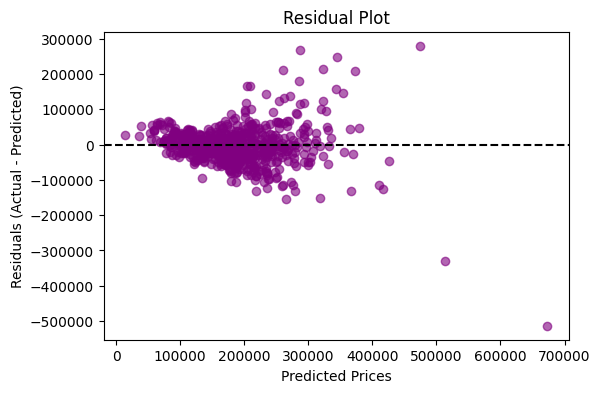

In [63]:
import matplotlib.pyplot as plt

# Residuals
residuals = y_test - predictions

plt.figure(figsize=(6,4))
plt.scatter(predictions, residuals, color='purple', alpha=0.6)
plt.axhline(y=0, color='black', linestyle='--')
plt.xlabel("Predicted Prices")
plt.ylabel("Residuals (Actual - Predicted)")
plt.title("Residual Plot")
plt.show()


The residual plot is used to examine differences between actual and predicted house prices. 

Ideally, residuals should be distributed around zero without a clear systematic pattern. 

The plot suggests that prediction erros may become more variable as predicted property prices increase. This could indicate heteroscedasticity, where the variance of prediction errors is not constant. 

A possible future improvement would be to investigate whether transforming the target variable or introducing additional property characteristics improves model performance. 

However, these changes have not been implemented in the current model. 

**Interpret coefficients in the context of the prediction:**


The coefficient for Gr_Liv_SF, Garage_Area are 143.47756103 and 86.00612276. These results tell use that for every additional 1 sqaure foot of groundfloor living area, the model predicts that the house price increases by approximately $143.48, this is only assuming that the groundfloor are remains the same. In terms of garage_size, for every additional 1 square foot of garage area, the model predicts the house price increases by approaxiamtely $86.01, assuming that the garage size remains the same. In relation to the intercept, although it gives us a negative value of -15,408.03 and that it is basically meaningless in the real-world, because a house cannot have a 0 size garage and groundfloor living area so when it is 0 for these features then the price of the house will be -$15,408.03. 


**Conclusions and Key Findings** 

This project investigated the relationship between garage area, above-ground living area and residential property sale prices in Ames, Iowa, using multiple linear regression.

*Key Findings* 
- Both garage area and above-ground living area demonstrated positive associations with property sale prices. 
- The model estimated an increase of approximately $143.48 per additional square foor of garage area, holding living area constant. 
- The model estimated an increase of approximately $86.01 per additional square foot of above-ground living area, holding garage area constant. 
- The model achieved an R2 score of approximately 0.57 on the test dataset, suggesting that the two predictions explain a meaningful proportion of variation in sale prices. 
- The RMSE of approximately $53,247 indicates that prediction erros remain substantial. 

**Limitations**
The model uses only two property characteristics and does not account for other potentially important factors, including neighbourhood, property condition, age and overall quality. 

**Future Improvements** 

Further analysis could explore additional explanatroy variables, investigate influential outliers, test alternative feature transformation and compare the model against baseline predictions. 

Overall, this project demonstrates how multiple linear regression can be used to investigate relationships between property characteristics and sale prices, while highlighting the importance of evaluating predictive accuracy and understanding model limitations. 

In [64]:
df_results = pd.DataFrame({
    'Actual_Price': y_test.ravel(),
    'Predicted_Price': predictions.ravel(),
    'Above_Ground_Living_Area': X_test[:, 1],
    'Garage_Area': X_test[:, 0]
})

df_results['Prediction_Error'] = (
    df_results['Actual_Price']
    - df_results['Predicted_Price']
)

df_results.to_csv(
    'house_price_predictions2.csv',
    index=False
)

print("Results saved to house_price_predictions2.csv")


Results saved to house_price_predictions2.csv
